In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/navyatripathi123/bank-marketing-practice01/bank-additional-full.csv
/kaggle/input/datasets/navyatripathi123/bank-marketing-practice01/bank-additional-names.txt
/kaggle/input/datasets/navyatripathi123/bank-marketing-practice01/bank-additional.csv
/kaggle/input/datasets/navyatripathi123/bank-marketing-practice01/bank-full.csv
/kaggle/input/datasets/navyatripathi123/bank-marketing-practice01/bank-names.txt
/kaggle/input/datasets/navyatripathi123/bank-marketing-practice01/bank.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
DATA_DIR = Path(
    "/kaggle/input/datasets/navyatripathi123/bank-marketing-practice01"
)

In [4]:
from pathlib import Path

# List datasets attached to this notebook
input_dir = Path("/kaggle/input")

for path in input_dir.iterdir():
    print(path)

/kaggle/input/datasets


In [5]:
input_dir = Path("/kaggle/input")

for file in input_dir.rglob("bank-full.csv"):
    print(file)

/kaggle/input/datasets/navyatripathi123/bank-marketing-practice01/bank-full.csv


In [6]:
df1 = pd.read_csv(DATA_DIR / "bank-full.csv", sep=";")
print("Shape:", df1.shape)
df1.head()

Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [7]:
df2 = pd.read_csv(DATA_DIR / "bank.csv", sep=";")
print("Shape:", df2.shape)
df2.head()

Shape: (4521, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [8]:
df3 = pd.read_csv(DATA_DIR / "bank-additional-full.csv", sep=";")
print("Shape:", df3.shape)
df3.head()

Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [9]:
df4 = pd.read_csv(DATA_DIR / "bank-additional.csv", sep=";")
print("Shape:", df4.shape)
df4.head()


Shape: (4119, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


# Dataset Overview:


1. df1 (bank-full.csv) and df2 (bank.csv):
    df2 is a subset of df1.
2. df3 (bank-additional-full.csv) and df4 (bank-additional.csv):
    df4 is a subset of df3.
3. Datasets with "additional" in their filenames (df3 and df4)
    contain 4 more features. (with different schemas)
4. the response of the person (y) is our target variable.

In [10]:
print("df1 (bank-full.csv) info:")
df1.info()

print("\ndf3 (bank-additional-full.csv) info:")
df3.info()

df1 (bank-full.csv) info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

df3 (bank-additional-full.csv) info:
<class 'pandas.core.frame.DataFrame

In [11]:
print("tARGET DISTRIBUTION IN df1", df1['y'].value_counts(normalize=True) * 100)
print("tARGET DISTRIBUTION IN df2", df2['y'].value_counts(normalize=True) * 100)
print("tARGET DISTRIBUTION IN df3", df3['y'].value_counts(normalize=True) * 100)
print("tARGET DISTRIBUTION IN df4", df4['y'].value_counts(normalize=True) * 100)

tARGET DISTRIBUTION IN df1 y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64
tARGET DISTRIBUTION IN df2 y
no     88.476001
yes    11.523999
Name: proportion, dtype: float64
tARGET DISTRIBUTION IN df3 y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64
tARGET DISTRIBUTION IN df4 y
no     89.05074
yes    10.94926
Name: proportion, dtype: float64


All the provided datasets exhibit a similar target variable distribution, with the positive response class (yes) being severely underrepresented compared to the negative response class (no). This indicates a significant class imbalance problem.

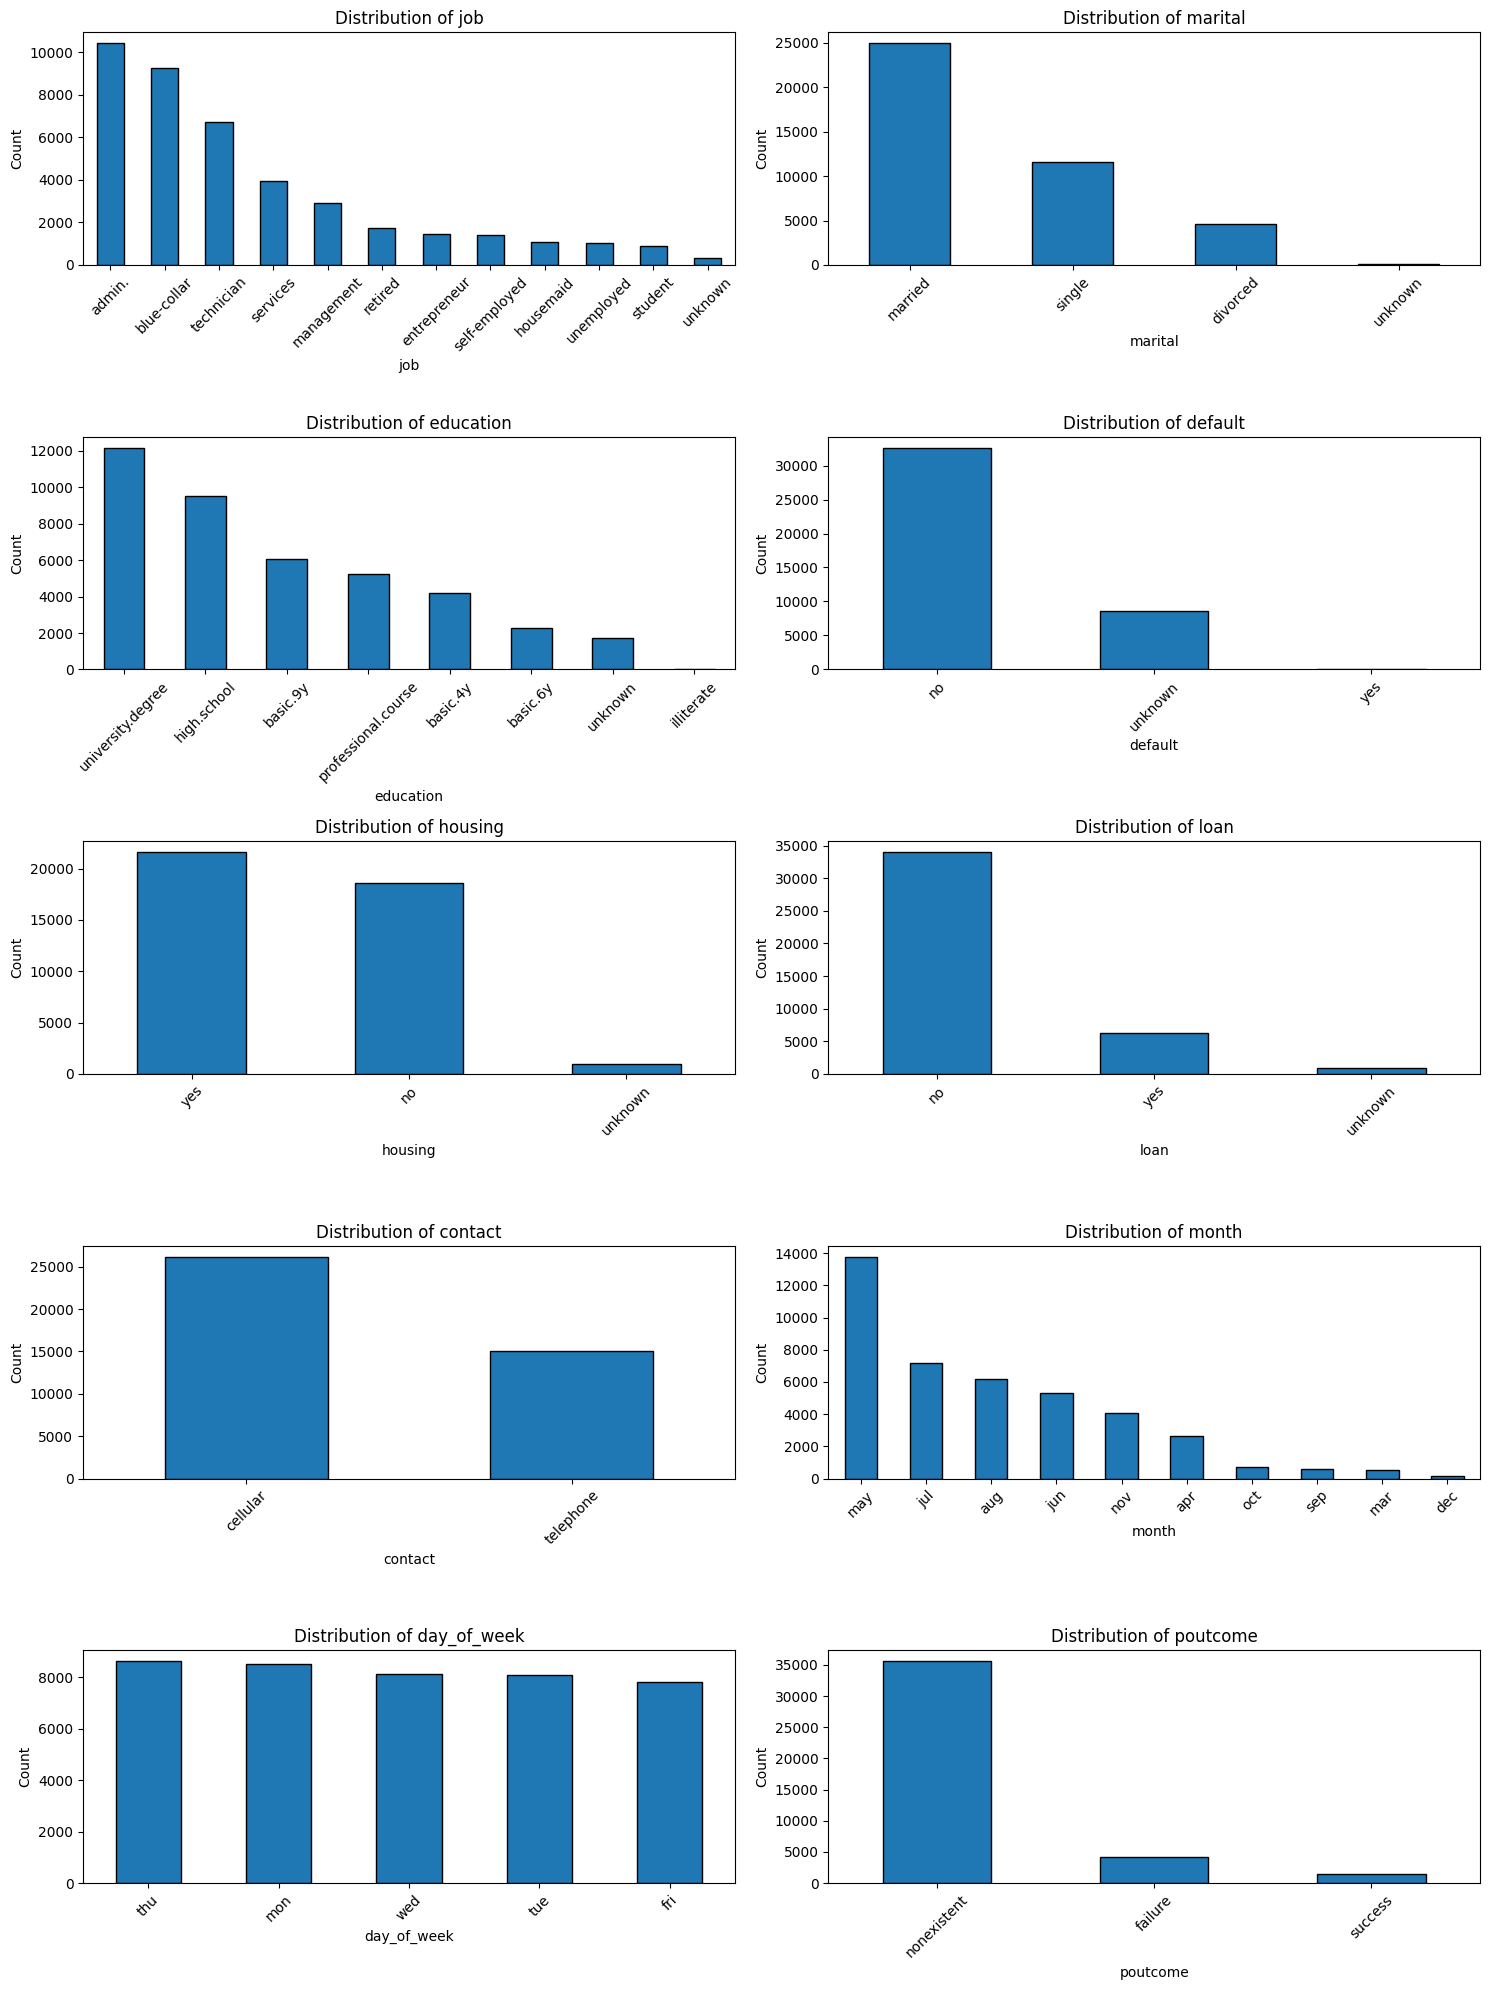

In [12]:
import math

cat_cols = df3.select_dtypes(
    include=["object", "category"]
).columns.drop("y", errors="ignore")

n_cols = 2
n_rows = math.ceil(len(cat_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, 4 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(cat_cols):
    counts = df3[col].value_counts(dropna=False)

    counts.plot(
        kind="bar",
        ax=axes[i],
        edgecolor="black"
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=45)

# Remove unused subplot axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [15]:
cat_cols = df3.select_dtypes(
    include=["object", "category"]
).columns.drop("y", errors="ignore")

for col in cat_cols:
    summary = (
        df3.groupby(col, dropna=False)["y"]
        .apply(lambda s: (s == "yes").mean() * 100)
        .sort_values(ascending=False)
    )

    print(f"\nSubscription rate by {col} (%)")
    print(summary.round(2))


Subscription rate by job (%)
job
student          31.43
retired          25.23
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.89
Name: y, dtype: float64

Subscription rate by marital (%)
marital
unknown     15.00
single      14.00
divorced    10.32
married     10.16
Name: y, dtype: float64

Subscription rate by education (%)
education
illiterate             22.22
unknown                14.50
university.degree      13.72
professional.course    11.35
high.school            10.84
basic.4y               10.25
basic.6y                8.20
basic.9y                7.82
Name: y, dtype: float64

Subscription rate by default (%)
default
no         12.88
unknown     5.15
yes         0.00
Name: y, dtype: float64

Subscription rate by housing (%)
housing
yes        11.62
no         10.88
unknown    10.81
Name: y, dtype: 

In [13]:
#duration feature is being dropped as it is unknown during capaign planning
df3=df3.drop(columns=['duration'])
df3.shape

(41188, 20)

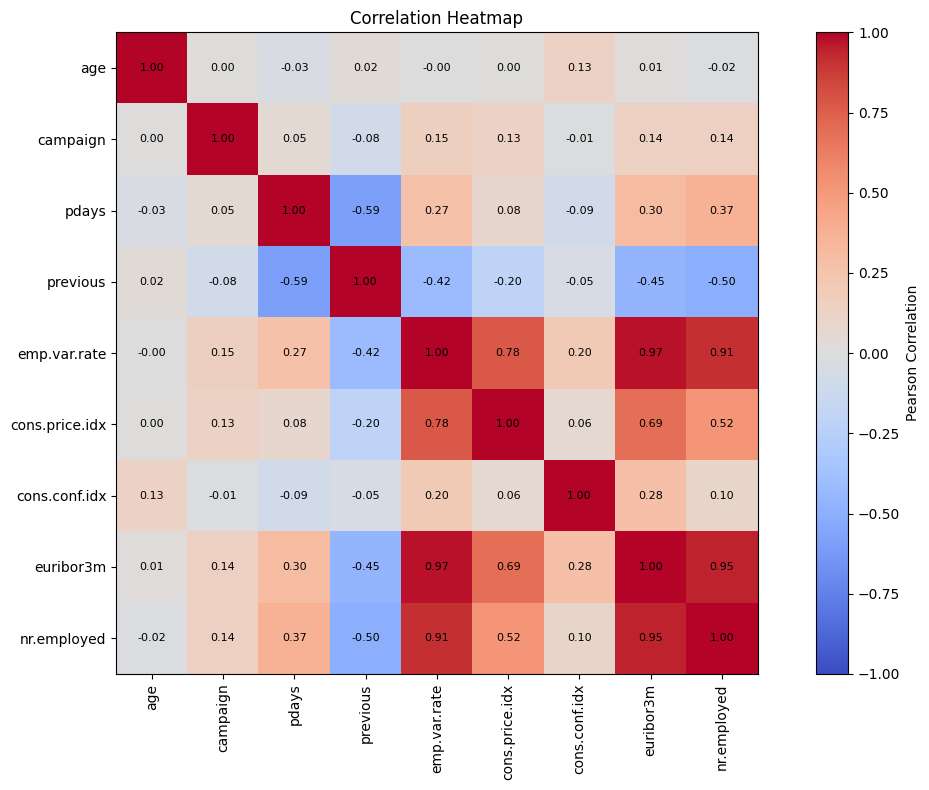

In [14]:
num_df = df3.select_dtypes(include=np.number)

# Correlation matrix
corr = num_df.corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(12, 8))

im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

# Axis labels
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)

# Add correlation values
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="Pearson Correlation")
ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()

the calculated indices and rates show high correlation amongst them

# COnclusion

